In [4]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pprint import pprint

In [5]:
#Getting the dataset and displaying it
df = pd.read_csv("cleaned_data.csv")
print("Shape of dataset:", df.shape,"\n\n\n")
print(df.head(5))
print("\n\n\nInformation:")
df.info()
print("\n\n\nDuplicated Rows:",df.duplicated().sum())

Shape of dataset: (266, 14) 



                  Country Name  EG.ELC.ACCS.ZS  FP.CPI.TOTL.ZG  \
0                  Afghanistan       85.300000       -4.644709   
1  Africa Eastern and Southern       50.667516        7.399186   
2   Africa Western and Central       57.064737        5.221168   
3                      Albania      100.000000        4.758346   
4                      Algeria      100.000000        9.322174   

   IT.NET.USER.ZS  NE.TRD.GNFS.ZS  NV.AGR.TOTL.ZS  NV.IND.TOTL.ZS  \
0       15.928400       66.999578       34.743247       13.449823   
1       27.800000       56.283721       15.305933       26.467975   
2       38.500000             NaN       24.321381       23.244644   
3       83.135592       82.352493       16.274239       23.160712   
4       76.197601       43.739798       13.369245       37.547655   

   NY.GDP.MKTP.KD.ZG  SL.UEM.TOTL.ZS  SP.DYN.IMRT.IN  \
0           2.266944       14.008000       49.900000   
1           1.941382        7.676548       4

In [6]:
# Removing aggregate rows and marking the hidden missing values in DominantSector
df = df[df["Region"] != "Aggregates"].reset_index(drop=True)
df["DominantSector"] = df["DominantSector"].replace("Missing", np.nan)
print("Shape of dataset:", df.shape)

Shape of dataset: (217, 14)


In [7]:
#Number of countries and other statistics
print("\n\n\nNumber of Countries:",len(df["Country Name"].unique()))
print("\n\n\nFeature Types:")
pprint(list(df.columns[1:-1]))

print("\n\n\nSummary of statistics of all variables:",df.describe())

print("\n\n\nClass counts (per HDI metrics):")
print("Low:",(df["HDI"] < 0.550).sum())
print("Medium/High:",((df["HDI"] < 0.800) & (df["HDI"] >= 0.550)).sum())
print("Very High:",(df["HDI"] >= 0.800).sum())




Number of Countries: 217



Feature Types:
['EG.ELC.ACCS.ZS',
 'FP.CPI.TOTL.ZG',
 'IT.NET.USER.ZS',
 'NE.TRD.GNFS.ZS',
 'NV.AGR.TOTL.ZS',
 'NV.IND.TOTL.ZS',
 'NY.GDP.MKTP.KD.ZG',
 'SL.UEM.TOTL.ZS',
 'SP.DYN.IMRT.IN',
 'Region',
 'ServiceSector',
 'DominantSector']



Summary of statistics of all variables:        EG.ELC.ACCS.ZS  FP.CPI.TOTL.ZG  IT.NET.USER.ZS  NE.TRD.GNFS.ZS  \
count      215.000000      177.000000      181.000000      176.000000   
mean        88.181860       10.167926       71.698269       94.836663   
std         22.431066       20.713952       25.340271       60.257990   
min          5.400000       -4.644709        7.172300        2.473729   
25%         88.350000        3.584526       59.187401       53.287087   
50%        100.000000        5.733163       81.705902       82.305251   
75%        100.000000        9.283074       91.000000      115.566354   
max        100.000000      221.341644      100.000000      402.566968   

       NV.AGR.TOTL.ZS  NV.IND.T

In [8]:
# These are dataframes based on HDI
df_low = df[df["HDI"] < 0.550]
df_medium_high = df[(df["HDI"] >= 0.550) & (df["HDI"] < 0.800)]
df_very_high = df[df["HDI"] >= 0.800]

In [9]:
#Showing missed vals n stuff
missing_df = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Percentage (%)': (df.isnull().sum() / len(df))*100
}).sort_values(by='Percentage (%)', ascending=False)
print(missing_df)

df_for_this = df.drop(columns=["Country Name","Region","DominantSector","HDI"])

missing_df_class1 = pd.DataFrame({
    'Missing Count': df_for_this[df["HDI"]<0.550].isnull().sum(),
    'Percentage (%)': (df_for_this[df["HDI"]<0.550].isnull().sum() / len(df_low))*100,
'Class':'Low'}).sort_values(by='Percentage (%)', ascending=False)
print(missing_df_class1)

missing_df_class2 = pd.DataFrame({
    'Missing Count': df_for_this[(df["HDI"] < 0.800) & (df["HDI"] >= 0.550)].isnull().sum(),
    'Percentage (%)': (df_for_this[(df["HDI"] < 0.800) & (df["HDI"] >= 0.550)].isnull().sum() / len(df_medium_high))*100,
'Class':'Medium/High'}).sort_values(by='Percentage (%)', ascending=False)
print(missing_df_class2)

missing_df_class3 = pd.DataFrame({
    'Missing Count': df_for_this[df["HDI"] >= 0.800].isnull().sum(),
    'Percentage (%)': (df_for_this[df["HDI"] >= 0.800].isnull().sum() / len(df_very_high))*100,
'Class':'Very High'}).sort_values(by='Percentage (%)', ascending=False)
print(missing_df_class3)

                   Missing Count  Percentage (%)
NE.TRD.GNFS.ZS                41       18.894009
FP.CPI.TOTL.ZG                40       18.433180
IT.NET.USER.ZS                36       16.589862
SL.UEM.TOTL.ZS                33       15.207373
HDI                           25       11.520737
NV.AGR.TOTL.ZS                23       10.599078
ServiceSector                 23       10.599078
DominantSector                23       10.599078
NV.IND.TOTL.ZS                21        9.677419
SP.DYN.IMRT.IN                21        9.677419
NY.GDP.MKTP.KD.ZG             13        5.990783
EG.ELC.ACCS.ZS                 2        0.921659
Country Name                   0        0.000000
Region                         0        0.000000
                   Missing Count  Percentage (%) Class
FP.CPI.TOTL.ZG                 5       19.230769   Low
IT.NET.USER.ZS                 5       19.230769   Low
NE.TRD.GNFS.ZS                 5       19.230769   Low
ServiceSector                  4       15.384

In [10]:
# HDI class column to compare coz we use this a lot
df["HDI_Class"] = pd.cut(df["HDI"], [0, 0.550, 0.800, 1.01], right=False, labels=["Low","Medium/High","Very High"])
df["HDI_Class"] = df["HDI_Class"].cat.add_categories("No HDI").fillna("No HDI")
print(df["HDI_Class"].value_counts())

HDI_Class
Medium/High    92
Very High      74
Low            26
No HDI         25
Name: count, dtype: int64


Country Name           object
EG.ELC.ACCS.ZS        float64
FP.CPI.TOTL.ZG        float64
IT.NET.USER.ZS        float64
NE.TRD.GNFS.ZS        float64
NV.AGR.TOTL.ZS        float64
NV.IND.TOTL.ZS        float64
NY.GDP.MKTP.KD.ZG     float64
SL.UEM.TOTL.ZS        float64
SP.DYN.IMRT.IN        float64
Region                 object
ServiceSector         float64
DominantSector         object
HDI                   float64
HDI_Class            category
dtype: object
                       Region DominantSector
count                     217            194
unique                      7              3
top     Europe & Central Asia        Service
freq                       58            184


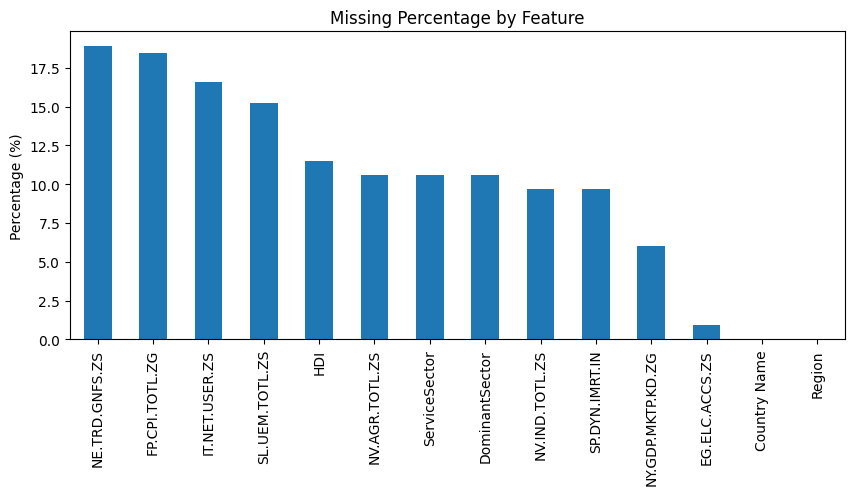

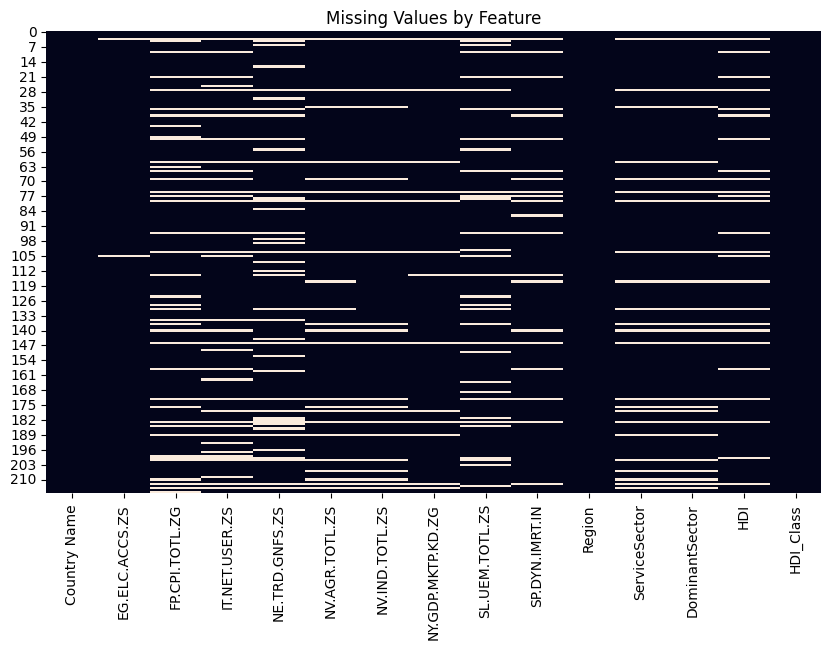

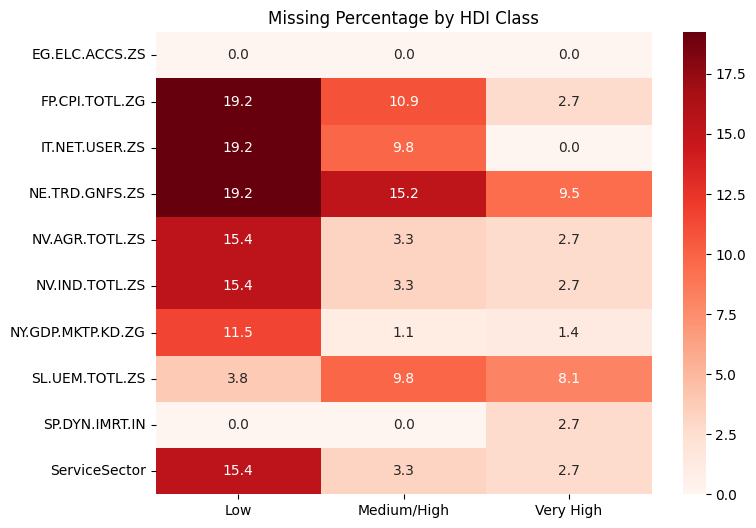

In [11]:
#feature types and missingness visualisation
print(df.dtypes)
print(df[["Region","DominantSector"]].describe())

missing_df["Percentage (%)"].plot(kind='bar', figsize=(10,4))
plt.title('Missing Percentage by Feature')
plt.ylabel('Percentage (%)')
plt.show()

plt.figure(figsize=(10,6))
sns.heatmap(df.isnull(), cbar=False)
plt.title('Missing Values by Feature')
plt.show()

missing_by_class = pd.DataFrame({
    'Low': missing_df_class1['Percentage (%)'],
    'Medium/High': missing_df_class2['Percentage (%)'],
    'Very High': missing_df_class3['Percentage (%)']})
plt.figure(figsize=(8,6))
sns.heatmap(missing_by_class, annot=True, cmap='Reds', fmt=".1f")
plt.title('Missing Percentage by HDI Class')
plt.show()

Shape of dataset: (141, 15) 



                   count       mean        std        min        25%  \
EG.ELC.ACCS.ZS     215.0  88.181860  22.431066   5.400000  88.350000   
FP.CPI.TOTL.ZG     177.0  10.167926  20.713952  -4.644709   3.584526   
IT.NET.USER.ZS     181.0  71.698269  25.340271   7.172300  59.187401   
NE.TRD.GNFS.ZS     176.0  94.836663  60.257990   2.473729  53.287087   
NV.AGR.TOTL.ZS     194.0   9.817042   9.937709   0.015094   2.138213   
NV.IND.TOTL.ZS     196.0  25.412233  12.281997   2.086302  17.607158   
NY.GDP.MKTP.KD.ZG  204.0   3.402970   6.806887 -29.433272   1.187805   
SL.UEM.TOTL.ZS     184.0   6.778283   5.520379   0.130000   3.163500   
SP.DYN.IMRT.IN     196.0  19.064286  17.268354   1.300000   4.975000   

                          50%         75%         max  
EG.ELC.ACCS.ZS     100.000000  100.000000  100.000000  
FP.CPI.TOTL.ZG       5.733163    9.283074  221.341644  
IT.NET.USER.ZS      81.705902   91.000000  100.000000  
NE.TRD.GNFS.ZS      82.

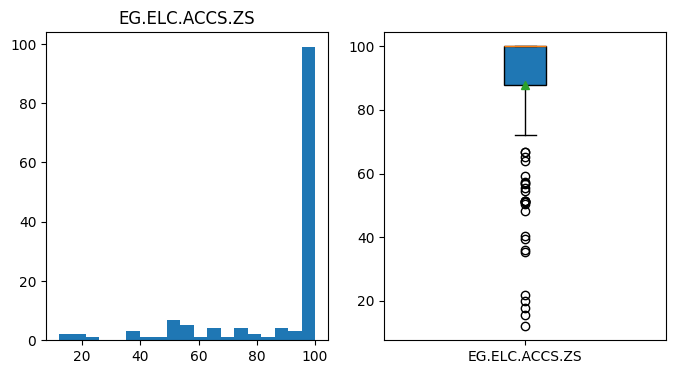

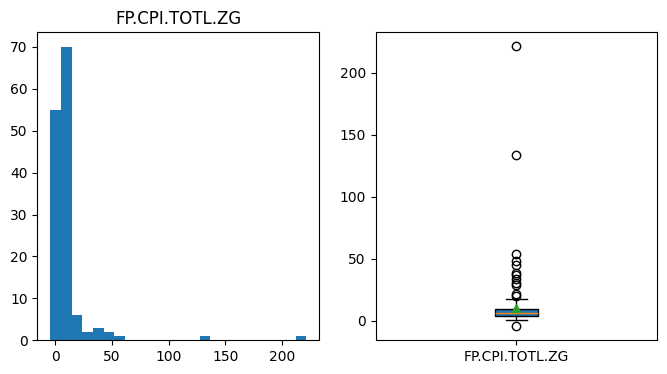

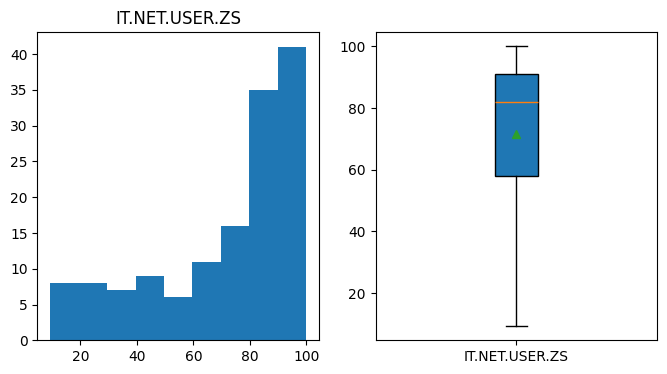

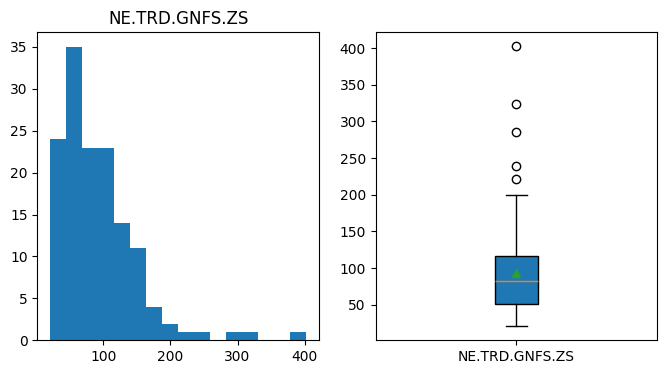

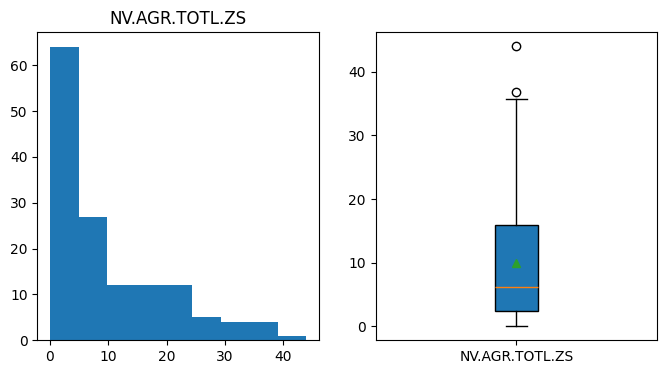

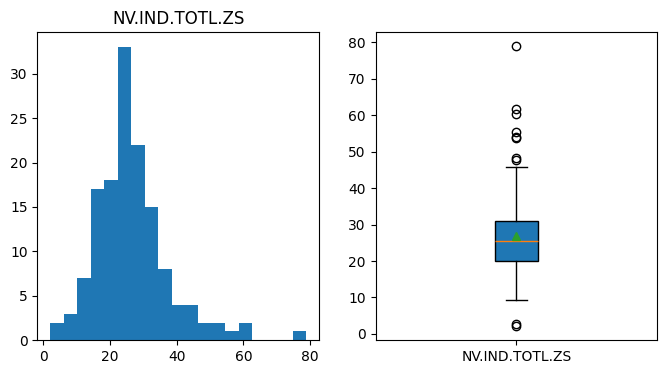

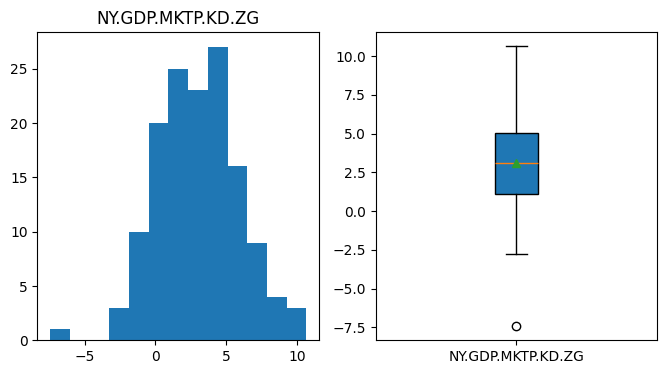

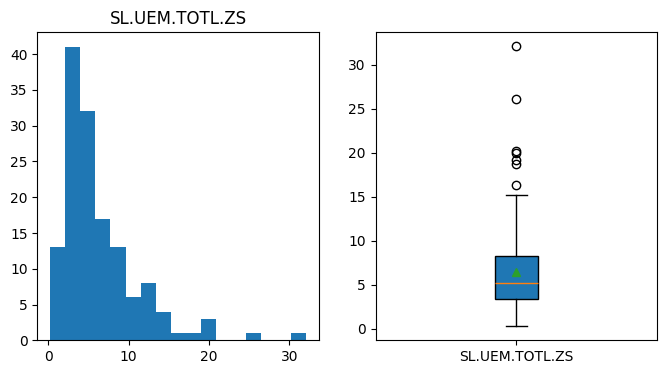

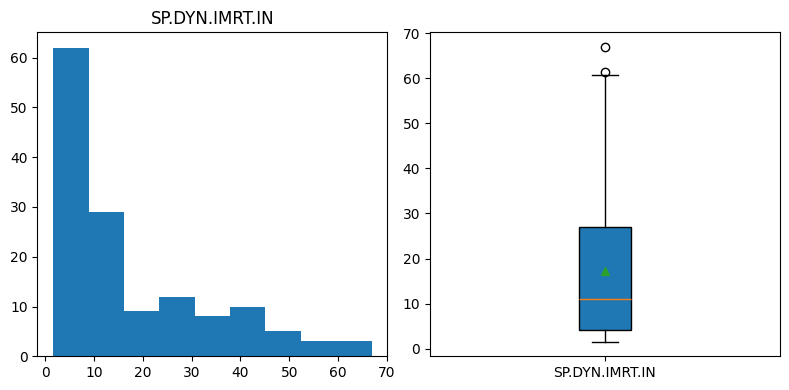

In [12]:
#Display all numerical vars
clean_df = df.dropna()
print("Shape of dataset:", clean_df.shape,"\n\n\n")
temp_list = list(clean_df.columns)[1:10]
print(df[temp_list].describe().T)
for nums in range(len(temp_list)):
  plt.figure(figsize=(8,4))
  plt.subplot(1,2,1)
  plt.hist(clean_df[temp_list[nums]],bins='auto')
  plt.title(temp_list[nums])
  plt.subplot(1,2,2)
  plt.boxplot(clean_df[temp_list[nums]],tick_labels=[temp_list[nums]],showmeans=True,patch_artist=True)

plt.tight_layout()
plt.show()


In [13]:
#skewness, IQR outliers, implausible entries and transformations from above's analysis
num_cols = temp_list + ["ServiceSector"]
pct_cols = ["EG.ELC.ACCS.ZS","IT.NET.USER.ZS","NV.AGR.TOTL.ZS","NV.IND.TOTL.ZS","SL.UEM.TOTL.ZS","ServiceSector"]
print("Entries outside 0-100 in percentage variables:",((df[pct_cols] < 0) | (df[pct_cols] > 100)).sum().sum())
print("Negative entries in trade and infant mortality:",(df[["NE.TRD.GNFS.ZS","SP.DYN.IMRT.IN"]] < 0).sum().sum())

for nums in num_cols:
  Q1 = df[nums].quantile(0.25)
  Q3 = df[nums].quantile(0.75)
  IQR = Q3 - Q1
  lower_bound = Q1 - 1.5 * IQR
  upper_bound = Q3 + 1.5 * IQR
  print(nums, "- Outliers:", ((df[nums] < lower_bound) | (df[nums] > upper_bound)).sum(), "Lower:", round(lower_bound,2), "Upper:", round(upper_bound,2))

df_wins = df.copy()
for nums in num_cols:
  df_wins[nums] = df[nums].clip(df[nums].quantile(0.01), df[nums].quantile(0.99))

log_cols = [nums for nums in num_cols if df[nums].min() >= 0]
skew_table = pd.DataFrame({"Raw": df[num_cols].skew(), "Winsorized": df_wins[num_cols].skew(), "Log1p": np.log1p(df[log_cols]).skew()})
print(skew_table)

Entries outside 0-100 in percentage variables: 0
Negative entries in trade and infant mortality: 0
EG.ELC.ACCS.ZS - Outliers: 39 Lower: 70.87 Upper: 117.48
FP.CPI.TOTL.ZG - Outliers: 17 Lower: -4.96 Upper: 17.83
IT.NET.USER.ZS - Outliers: 2 Lower: 11.47 Upper: 138.72
NE.TRD.GNFS.ZS - Outliers: 7 Lower: -40.13 Upper: 208.99
NV.AGR.TOTL.ZS - Outliers: 1 Lower: -19.02 Upper: 37.39
NV.IND.TOTL.ZS - Outliers: 8 Lower: -2.46 Upper: 51.06
NY.GDP.MKTP.KD.ZG - Outliers: 8 Lower: -4.51 Upper: 10.68
SL.UEM.TOTL.ZS - Outliers: 13 Lower: -4.73 Upper: 16.32
SP.DYN.IMRT.IN - Outliers: 3 Lower: -32.22 Upper: 66.97
ServiceSector - Outliers: 1 Lower: 20.45 Upper: 108.46
                        Raw  Winsorized     Log1p
EG.ELC.ACCS.ZS    -1.967634   -1.942913 -3.199393
FP.CPI.TOTL.ZG     7.501642    3.361465       NaN
IT.NET.USER.ZS    -1.002954   -0.991662 -1.800486
NE.TRD.GNFS.ZS     2.213364    2.023512 -0.657574
NV.AGR.TOTL.ZS     1.174373    1.105660 -0.084528
NV.IND.TOTL.ZS     1.088853    0.836633

                                                   Count  Percentage
Region                                                              
Europe & Central Asia                                 58   26.728111
Sub-Saharan Africa                                    48   22.119816
Latin America & Caribbean                             42   19.354839
East Asia & Pacific                                   37   17.050691
Middle East, North Africa, Afghanistan & Pakistan     23   10.599078
South Asia                                             6    2.764977
North America                                          3    1.382488
                Count  Percentage
DominantSector                   
Service           184   94.845361
Industry            8    4.123711
Agriculture         2    1.030928


/tmp/ipykernel_1732/1979156240.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=clean_df, x=temp_list_disc[nums], palette='viridis')


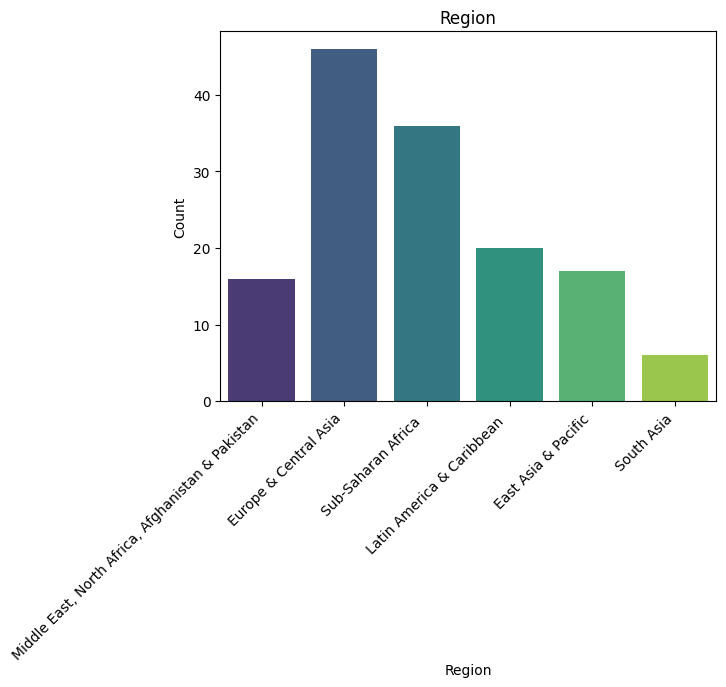

/tmp/ipykernel_1732/1979156240.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=clean_df, x=temp_list_disc[nums], palette='viridis')


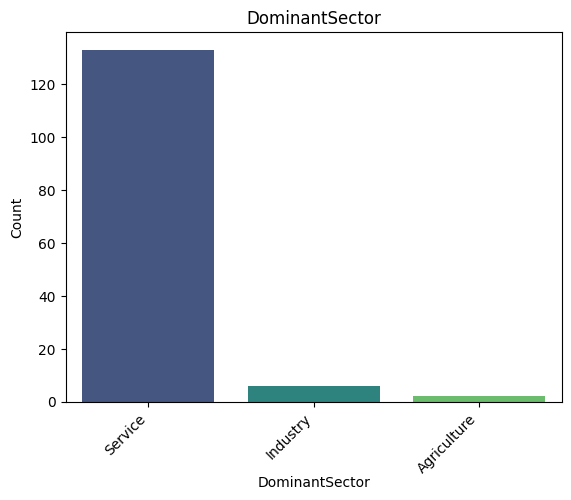

In [14]:
#Same for categorical variables
temp_list_disc = ['Region','DominantSector']

class_counts = df['Region'].value_counts()
class_props = df['Region'].value_counts(normalize=True) * 100

freq_table = pd.DataFrame({'Count': class_counts, 'Percentage': class_props})
print(freq_table)

class_counts = df['DominantSector'].value_counts()
class_props = df['DominantSector'].value_counts(normalize=True) * 100

freq_table = pd.DataFrame({'Count': class_counts, 'Percentage': class_props})
print(freq_table)

for nums in range(len(temp_list_disc)):
  sns.countplot(data=clean_df, x=temp_list_disc[nums], palette='viridis')
  plt.title(temp_list_disc[nums])
  plt.xlabel(temp_list_disc[nums],labelpad=0.5)
  plt.xticks(rotation=45, ha='right')
  plt.ylabel('Count')
  plt.show()

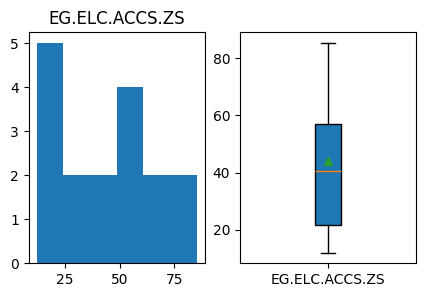

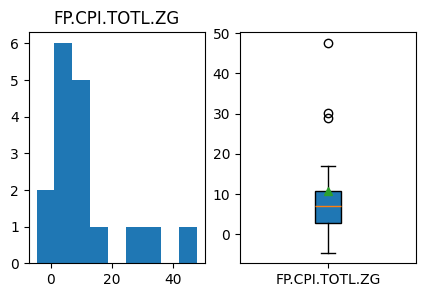

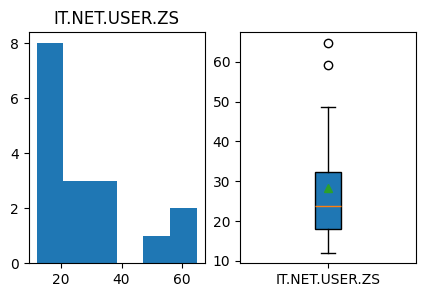

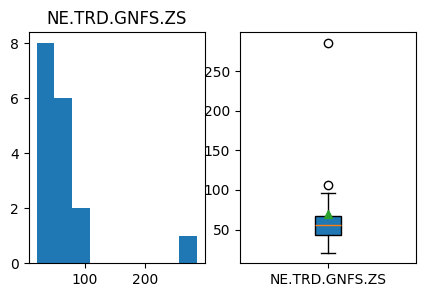

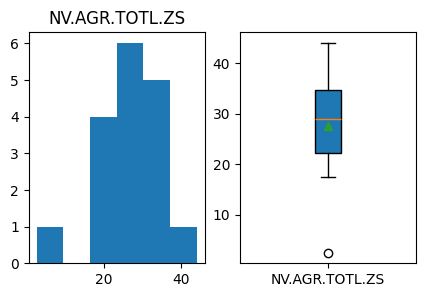

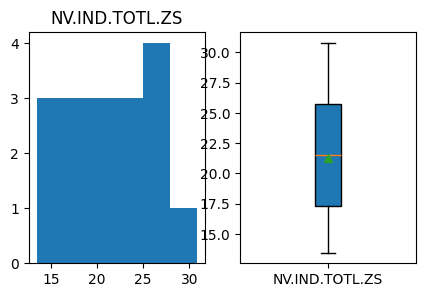

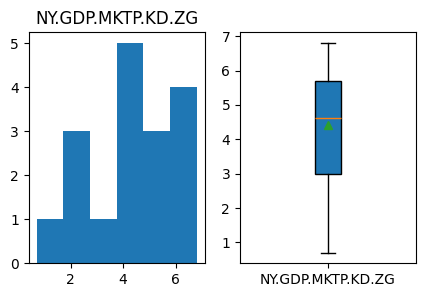

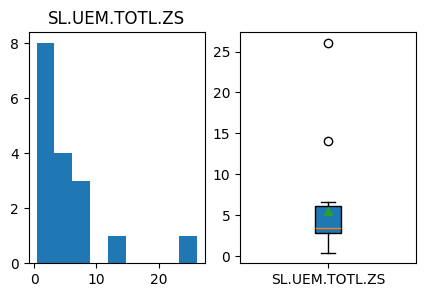

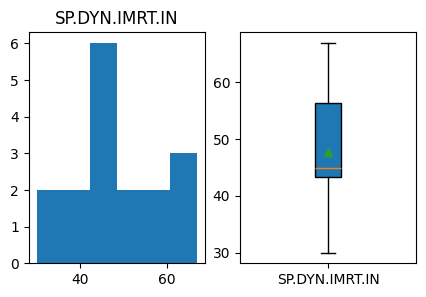

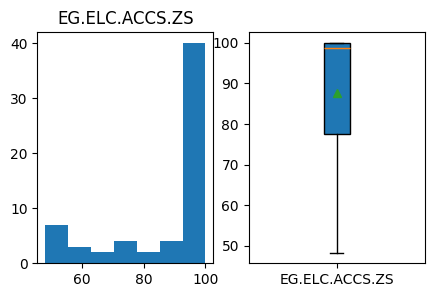

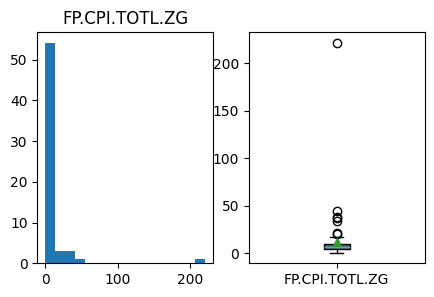

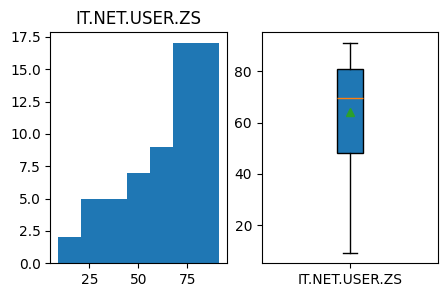

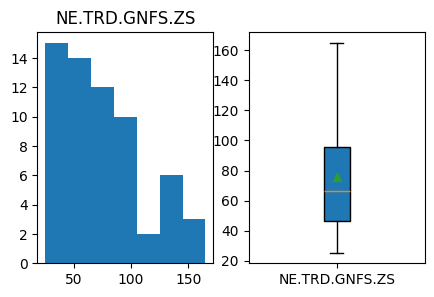

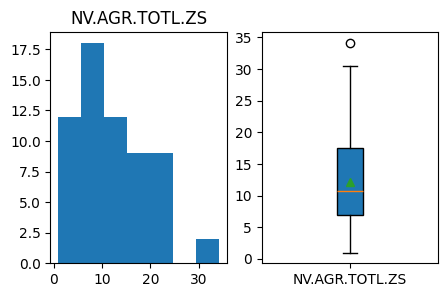

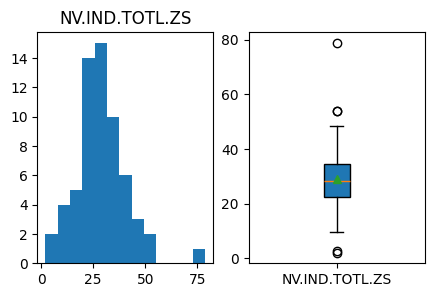

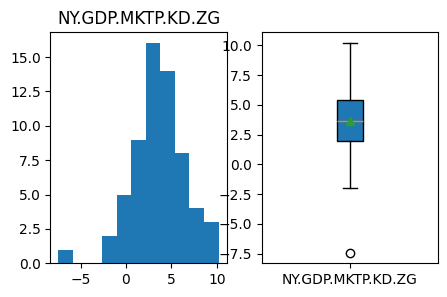

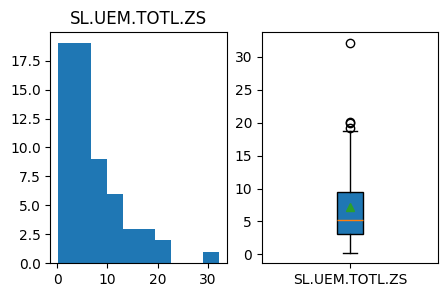

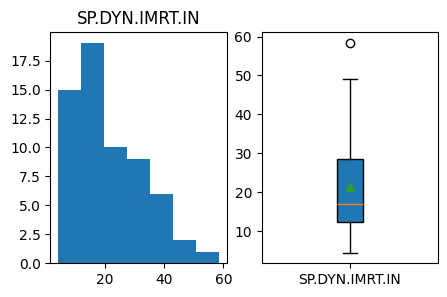

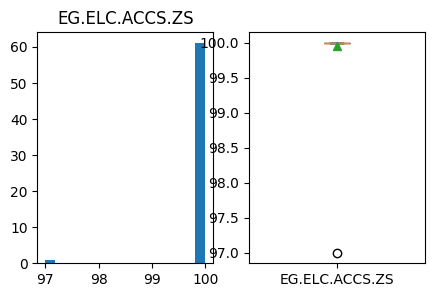

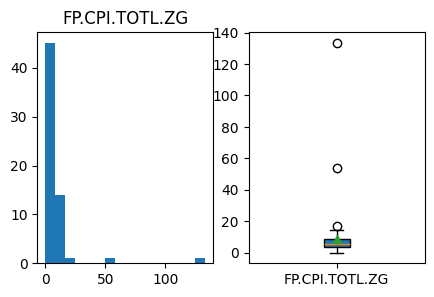

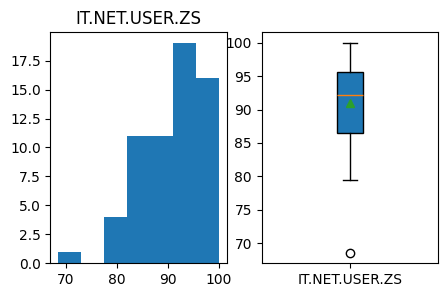

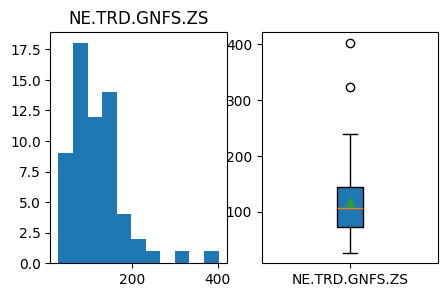

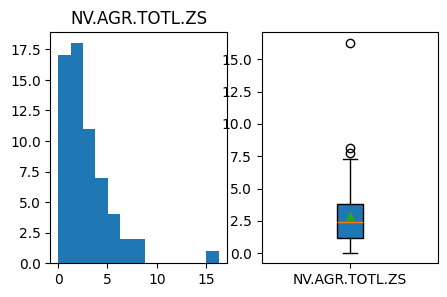

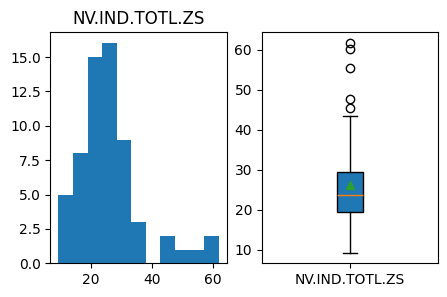

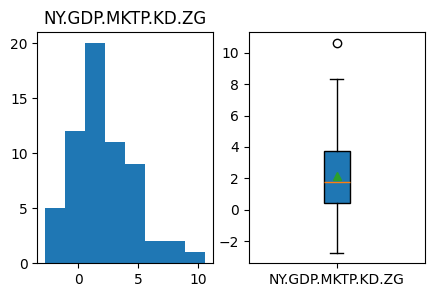

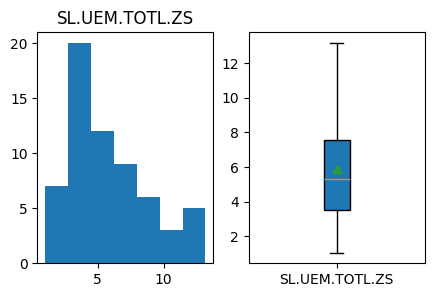

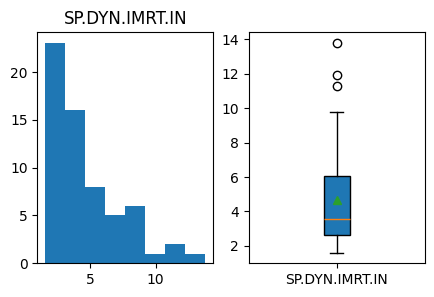

In [15]:
#Display stuff for the 3 classes to see variations
clean_df_low = df_low.dropna()
temp_df_low_cols = list(clean_df_low.columns)[1:10]
for nums in temp_df_low_cols:
  plt.figure(figsize=(5,3))
  plt.subplot(1,2,1)
  plt.hist(clean_df_low[nums],bins='auto')
  plt.title(nums)
  plt.subplot(1,2,2)
  plt.boxplot(clean_df_low[nums],tick_labels=[nums],showmeans=True,patch_artist=True)
  plt.show()

clean_df_med_high = df_medium_high.dropna()
for nums in temp_df_low_cols:
  plt.figure(figsize=(5,3))
  plt.subplot(1,2,1)
  plt.hist(clean_df_med_high[nums],bins='auto')
  plt.title(nums)
  plt.subplot(1,2,2)
  plt.boxplot(clean_df_med_high[nums],tick_labels=[nums],showmeans=True,patch_artist=True)
  plt.show()

clean_df_very_high = df_very_high.dropna()
for nums in temp_df_low_cols:
  plt.figure(figsize=(5,3))
  plt.subplot(1,2,1)
  plt.hist(clean_df_very_high[nums],bins='auto')
  plt.title(nums)
  plt.subplot(1,2,2)
  plt.boxplot(clean_df_very_high[nums],tick_labels=[nums],showmeans=True,patch_artist=True)
  plt.show()

HDI_Class                       Low  Medium/High   Very High
EG.ELC.ACCS.ZS    median  45.400000    99.100000  100.000000
                  mean    44.980769    88.439130   99.941892
                  std     25.144399    17.876032    0.378174
FP.CPI.TOTL.ZG    median   7.126975     6.026635    5.033869
                  mean    11.977225    11.826889    7.957995
                  std     13.301231    25.366367   16.397594
IT.NET.USER.ZS    median  23.713600    70.187202   92.216438
                  mean    26.952057    65.520054   90.560708
                  std     15.056281    20.523371    7.187633
NE.TRD.GNFS.ZS    median  55.286797    74.956267  107.277802
                  mean    66.530584    77.144306  122.753366
                  std     56.900899    34.422219   75.374971
NV.AGR.TOTL.ZS    median  28.961000     9.920603    2.139215
                  mean    27.296654    12.025611    2.627987
                  std      9.354818     7.580539    2.542424
NV.IND.TOTL.ZS    median

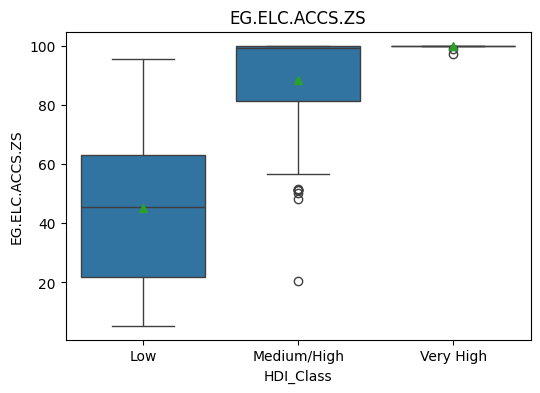

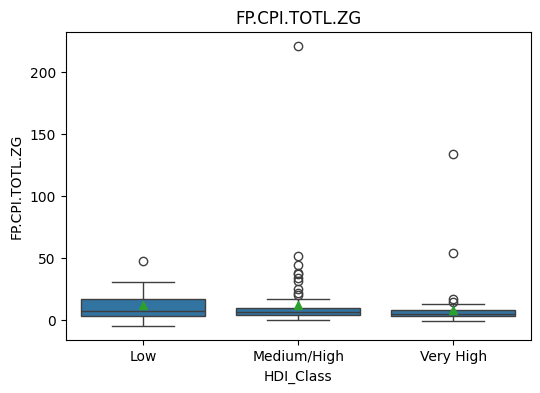

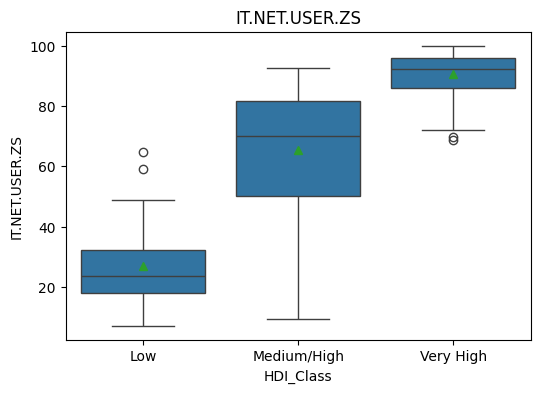

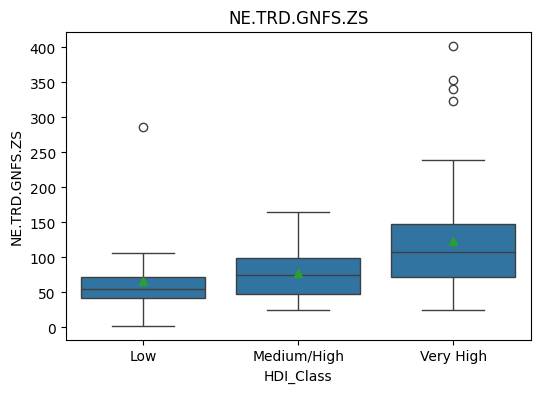

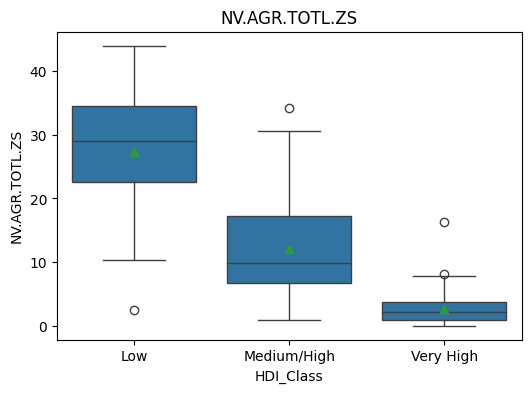

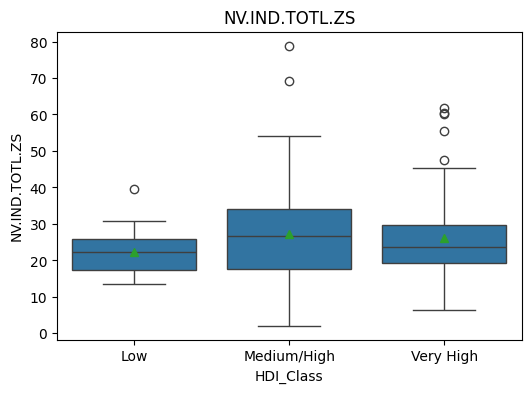

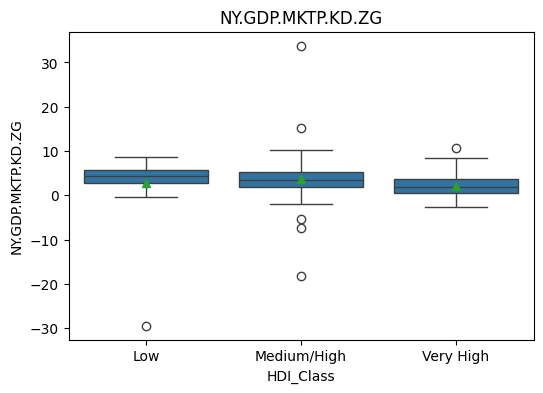

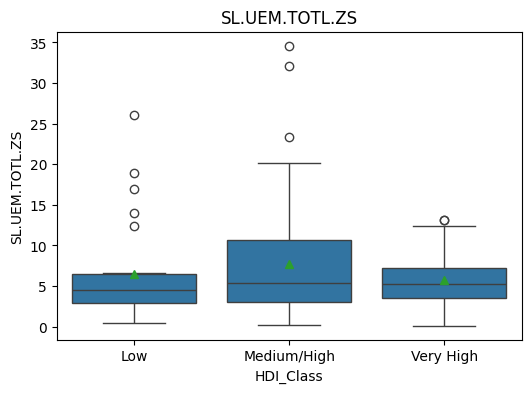

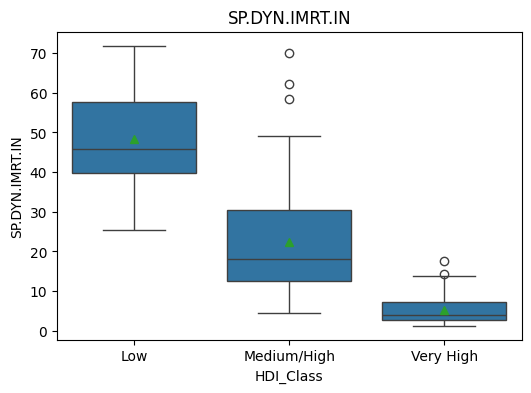

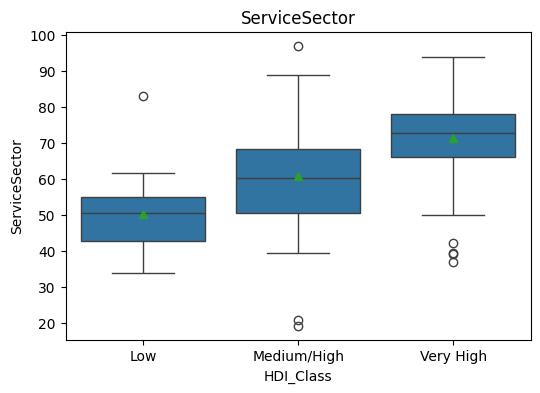

In [16]:
#Comparison of numerical indicators across HDI classes
df_classes = df[df["HDI_Class"] != "No HDI"]
print(df_classes.groupby("HDI_Class", observed=True)[num_cols].agg(["median","mean","std"]).T)

for nums in num_cols:
  plt.figure(figsize=(6,4))
  sns.boxplot(x="HDI_Class", y=nums, data=df_classes, order=["Low","Medium/High","Very High"], showmeans=True)
  plt.title(nums)
  plt.show()

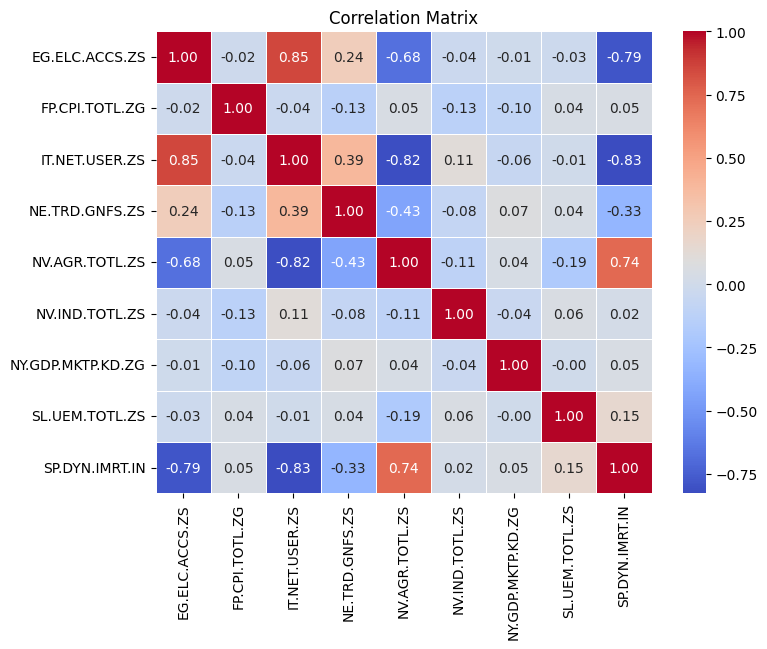

In [17]:
#Heatmap seeing
corr_matrix = df[temp_list].corr(method='pearson')

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Matrix')
plt.show()

Region Analysis
                                                   Frequency  Proportion (%)
Region                                                                      
Europe & Central Asia                                     58           26.73
Sub-Saharan Africa                                        48           22.12
Latin America & Caribbean                                 42           19.35
East Asia & Pacific                                       37           17.05
Middle East, North Africa, Afghanistan & Pakistan         23           10.60
South Asia                                                 6            2.76
North America                                              3            1.38


DominantSector Analysis
                Frequency  Proportion (%)
DominantSector                           
Service               184           84.79
NaN                    23           10.60
Industry                8            3.69
Agriculture             2            0.92


Cross-Tabul

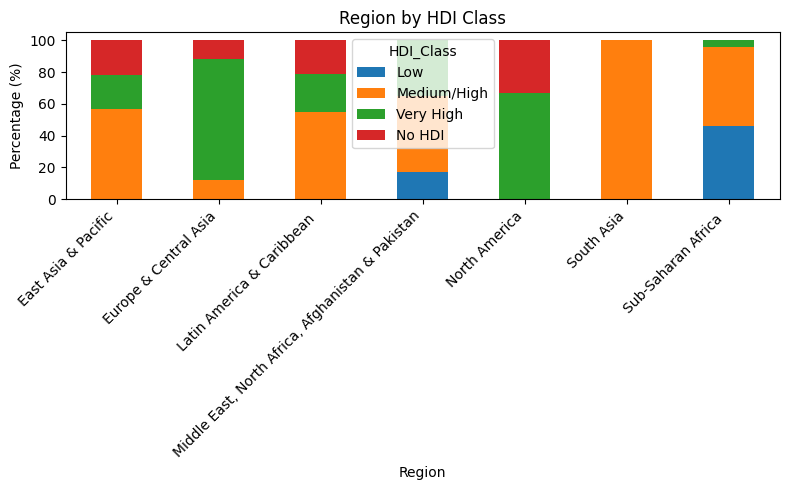

DominantSector vs HDI_Class (Counts)
HDI_Class       Low  Medium/High  Very High  No HDI  All
DominantSector                                          
Agriculture       2            0          0       0    2
Industry          0            4          4       0    8
Service          20           85         68      11  184
All              22           89         72      11  194


DominantSector vs HDI_Class (Row Proportions in %)
HDI_Class          Low  Medium/High  Very High  No HDI
DominantSector                                        
Agriculture     100.00          0.0       0.00    0.00
Industry          0.00         50.0      50.00    0.00
Service          10.87         46.2      36.96    5.98




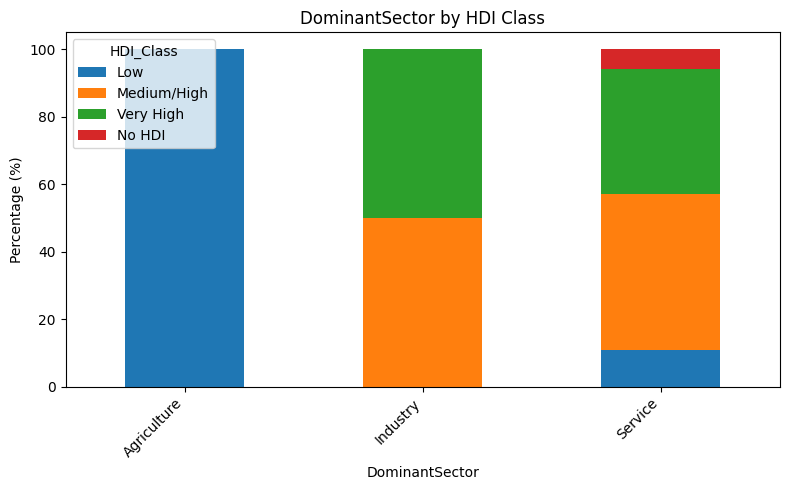

In [23]:
#Frequency analysis and cross-tabulations for the categorical variables as well as stacked bar graphs
temp_list_disc = ['Region','DominantSector']

for nums in temp_list_disc:
  freq_table = pd.DataFrame({
      'Frequency': df[nums].value_counts(dropna=False),
      'Proportion (%)': df[nums].value_counts(normalize=True, dropna=False) * 100
  }).round(2)
  print(nums, "Analysis")
  print(freq_table)
  print("\n")

cross_tab_counts = pd.crosstab(df['Region'], df['DominantSector'], margins=True)
print("Cross-Tabulation Region vs DominantSector (Counts)")
print(cross_tab_counts)
print("\n")

cross_tab_props = pd.crosstab(df['Region'], df['DominantSector'], normalize='index') * 100
print("Cross-Tabulation Region vs DominantSector (Row Proportions in %)")
print(cross_tab_props.round(2))
print("\n")

for nums in temp_list_disc:
  cross_tab_class = pd.crosstab(df[nums], df['HDI_Class'], margins=True)
  cross_tab_class_props = pd.crosstab(df[nums], df['HDI_Class'], normalize='index') * 100
  print(nums, "vs HDI_Class (Counts)")
  print(cross_tab_class)
  print("\n")
  print(nums, "vs HDI_Class (Row Proportions in %)")
  print(cross_tab_class_props.round(2))
  print("\n")
  cross_tab_class_props.plot(kind='bar', stacked=True, figsize=(8, 5))
  plt.title(nums + ' by HDI Class')
  plt.ylabel('Percentage (%)')
  plt.xticks(rotation=45, ha='right')
  plt.tight_layout()
  plt.show()

HDI_Class            Low  Medium/High  Very High  No HDI
EG.ELC.ACCS.ZS      0.00         0.00       0.00     8.0
FP.CPI.TOTL.ZG     19.23        10.87       2.70    92.0
IT.NET.USER.ZS     19.23         9.78       0.00    88.0
NE.TRD.GNFS.ZS     19.23        15.22       9.46    60.0
NV.AGR.TOTL.ZS     15.38         3.26       2.70    56.0
NV.IND.TOTL.ZS     15.38         3.26       2.70    48.0
NY.GDP.MKTP.KD.ZG  11.54         1.09       1.35    32.0
SL.UEM.TOTL.ZS      3.85         9.78       8.11    68.0
SP.DYN.IMRT.IN      0.00         0.00       2.70    76.0
ServiceSector      15.38         3.26       2.70    56.0


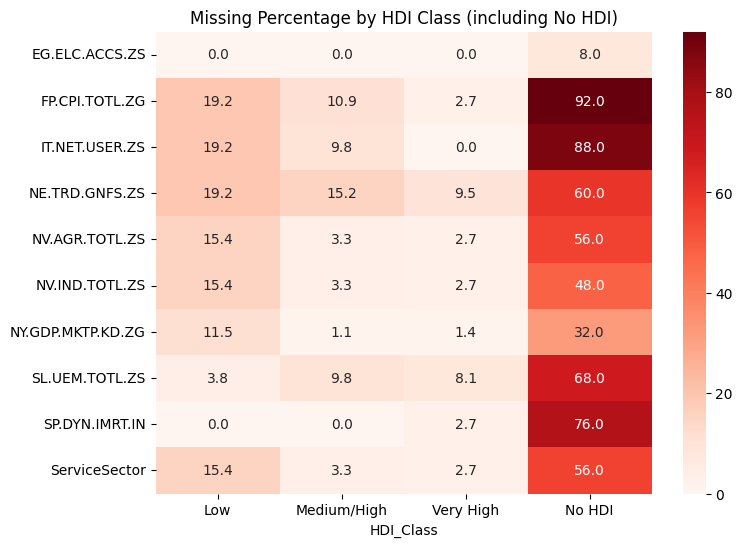

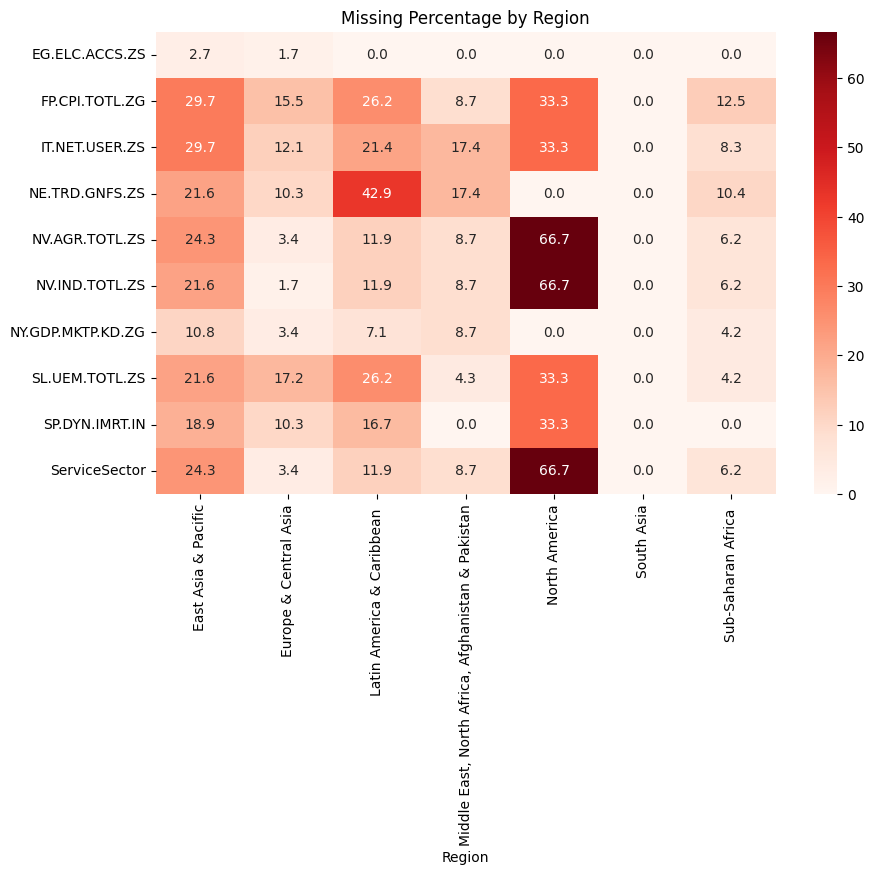

HDI                                                False  True 
Region                                                         
East Asia & Pacific                                   29      8
Europe & Central Asia                                 51      7
Latin America & Caribbean                             33      9
Middle East, North Africa, Afghanistan & Pakistan     23      0
North America                                          2      1
South Asia                                             6      0
Sub-Saharan Africa                                    48      0
             Before dropna  After dropna
HDI_Class                               
Medium/High             92            62
Very High               74            62
Low                     26            17
No HDI                  25             0


In [21]:
#last part about missingness and development
missing_by_class_all = df[num_cols].isnull().groupby(df["HDI_Class"], observed=True).mean().T * 100
print(missing_by_class_all.round(2))
plt.figure(figsize=(8,6))
sns.heatmap(missing_by_class_all, annot=True, cmap='Reds', fmt=".1f")
plt.title('Missing Percentage by HDI Class (including No HDI)')
plt.show()

missing_by_region = df[num_cols].isnull().groupby(df["Region"]).mean().T * 100
plt.figure(figsize=(10,6))
sns.heatmap(missing_by_region, annot=True, cmap='Reds', fmt=".1f")
plt.title('Missing Percentage by Region')
plt.show()

print(pd.crosstab(df["Region"], df["HDI"].isnull()))
print(pd.DataFrame({"Before dropna": df["HDI_Class"].value_counts(), "After dropna": clean_df["HDI_Class"].value_counts()}))